In [1]:
import sys

sys.path.append('..')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn import metrics
from sklearn.metrics import auc, roc_curve, confusion_matrix, ConfusionMatrixDisplay
import os
import random
from natsort import natsorted, index_natsorted

import torch
import torchvision
from PIL import Image
import time
import copy
import tqdm
import torchvision.models as models

import wandb   
from statistics import mode
import re

from torch.utils.data import WeightedRandomSampler

from typing import Any, Callable, cast, Dict, List, Optional, Tuple, Union

# from multi_to_binary import multi_to_binary

device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")
print(device)

cuda:1


In [2]:
iteration = '01'

# parameters
path = '../../data/semi-processed/supervised/multiview'
seed = 42
batch_size = 96


training_dir = f'../../data/semi-processed/supervised/growing_multiview_training'

mask = False
if mask:
    masked = '_mask'
else:
    masked = ''

print(f'Using {training_dir} for training')

Using ../../data/semi-processed/supervised/growing_multiview_training for training


In [3]:
# Specifying data augmentation transforms

class transforms_composed:
    """Rotate by one of the given angles."""

    def __init__(self, mode, apply=True, mask=False):
        self.mode = mode
        self.mask=False
        self.size = (224,224)
        if mask:
            self.mask = True
            mask = Image.open('../assets/dicom-mask.png')
            mask.load()
            mask = mask.resize(self.size,Image.NEAREST)
            masking_array = (np.array(mask)[:,:,3])
            masking_array[masking_array!=0]=1
            self.masking_array = (masking_array.astype(float)-1)*-1
        self.apply = apply
        self.randomResizedCrop = torchvision.transforms.RandomResizedCrop((self.size[1],self.size[0]), scale=(0.8, 1.0), ratio=(0.75, 1.3333333333333333), antialias=True)
        self.randomRotate = torchvision.transforms.RandomRotation(30)
        self.xflip = torchvision.transforms.RandomHorizontalFlip(p=0.5)
        self.resize = torchvision.transforms.Resize((self.size[1],self.size[0]), antialias=True)

    def __call__(self, x):
        tensorconvert=torchvision.transforms.ToTensor()
        if self.mode=='train' and self.apply:
            x = tensorconvert(x)
            if self.mask:
                x = x*self.masking_array
            if random.random()>0.15:
                x=torchvision.transforms.functional.adjust_brightness(x,np.amax((0.1,1+np.random.randn()*0.25)))
            if random.random()>0.15:
                x=torchvision.transforms.functional.adjust_contrast(x,np.amax((0.1,1+np.random.randn()*0.25)))
            if random.random()>0.15:
                x = self.randomResizedCrop(x)
                x = self.randomRotate(x)
                x=self.xflip(x)
            else:
                x = self.resize(x)
            # x = torch.unsqueeze(x[0,:,:],0)
        else:
            x = tensorconvert(x)
            x = self.resize(x)
            if self.mask:
                x = x*self.masking_array
            # x = torch.unsqueeze(x[0,:,:],0)
        return x.type(torch.float)

train_transforms = transforms_composed('train', mask=mask)
valtest_transforms = transforms_composed('valtest', mask=mask)

In [4]:
# load the data sets for multiclass classification model

data_dir = f'{path}'

train_dataset = torchvision.datasets.ImageFolder(training_dir, train_transforms)
val_dataset = torchvision.datasets.ImageFolder(os.path.join(data_dir, 'val'),valtest_transforms)
test_dataset = torchvision.datasets.ImageFolder(os.path.join(data_dir, 'test'),valtest_transforms)

class_names = train_dataset.classes


# weighted random sampling for imbalanced classes:
class_sample_count = np.array([len(os.listdir(training_dir+'/'+name)) for name in class_names])
weight = 1. / class_sample_count
samples_weight = np.array([weight[t] for t in train_dataset.targets])

samples_weight = torch.from_numpy(samples_weight)
samples_weight = samples_weight.double()
sampler = WeightedRandomSampler(samples_weight, len(samples_weight))


train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, num_workers=8, sampler = sampler)
# train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, num_workers=8, shuffle=True)
val_dataloader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size, num_workers=8)
test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=1, shuffle=True, num_workers=1)

dataloaders = {'train':train_dataloader,'val':val_dataloader,'test':test_dataloader}
# dataloaders_no_aug = {'train':train_dataloader_no_transforms,'val':val_dataloader,'test':test_dataloader}

In [5]:
print(class_names)
print(len(class_names))

['deep_tg_col_a', 'dta_sax', 'dta_sax_arch', 'me_2_ch', 'me_2_ch_col_m', 'me_4_ch', 'me_4_ch_col_m', 'me_4_ch_col_t', 'me_5_ch', 'me_5_ch_col', 'me_av_sax', 'me_av_sax_col', 'me_bicaval', 'me_bicaval_col', 'me_in_out', 'me_in_out_col_p', 'me_in_out_col_t', 'me_lax', 'me_lax_col_a', 'me_lax_col_m', 'me_lax_col_mv_av', 'me_mit_com', 'me_mit_com_col_m', 'other', 'tg_basal_sax', 'tg_mid_pap_sax', 'ue_asc_ao_sax']
27


In [7]:
# def train_model(model, criterion, optimizer, dataloaders, selected_class = 'multiclass', num_epochs=25):
#     since = time.time()

#     best_model_wts = copy.deepcopy(model.state_dict())
#     best_acc = 0.0

#     for epoch in range(num_epochs):
#         print(f'Epoch {epoch}/{num_epochs - 1}')
#         print('-' * 10)

#         # Each epoch has a training and validation phase
#         for phase in ['train', 'val']:
#             if phase == 'train':
#                 model.train()  # Set model to training mode
#             else:
#                 model.eval()   # Set model to evaluate mode

#             running_loss = 0.0
#             running_corrects = 0

#             # Iterate over data.
#             for inputs, labels in dataloaders[phase]:
#                 inputs = inputs.to(device)
#                 labels = labels.to(device)
                
#                 # zero the parameter gradients
#                 optimizer.zero_grad()

#                 # forward
#                 # track history if only in train
#                 with torch.set_grad_enabled(phase == 'train'):
#                     outputs = model(inputs)
#                     _, preds = torch.max(outputs, 1)
#                     loss = criterion(outputs, labels)

#                     # backward + optimize only if in training phase
#                     if phase == 'train':
#                         loss.backward()
#                         optimizer.step()

#                 # statistics
#                 running_loss += loss.item() * inputs.size(0)
#                 running_corrects += torch.sum(preds == labels.data)
                

#             epoch_loss = running_loss / len(dataloaders[phase].dataset)
#             epoch_acc = running_corrects.double() / len(dataloaders[phase].dataset)
            
#             if phase == 'train':
#                 wandb.log({"loss": epoch_loss,})
#             elif phase == 'val':
#                 wandb.log({"val_loss": epoch_loss,})

#             print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

#             # deep copy the model
#             if phase == 'val' and epoch_acc > best_acc:
#                 best_acc = epoch_acc
#                 best_model_wts = copy.deepcopy(model.state_dict())

#         print()

#     time_elapsed = time.time() - since
#     print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
#     print(f'Best val Acc: {best_acc:4f}')

#     # load best model weights
#     model.load_state_dict(best_model_wts)
#     torch.save(model.state_dict(), f'../experiments/multiclass_view_model_{iteration}.pt')
#     return model

In [8]:
# #train multiclass model (2 days)

# #EfficientNet V2
# model = models.efficientnet_v2_l(num_classes=len(class_names), dropout=0.2).to(device)  # Biggo model

# criterion = torch.nn.CrossEntropyLoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=0.0002)

# model_ft = train_model(model, criterion, optimizer, dataloaders, num_epochs=20)

In [6]:
# functions
def plot_auroc (y_actual, y_scores, title):
    fpr, tpr, _thresholds = roc_curve(y_actual, y_scores)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(2, 2))
    plt.plot(
        fpr,
        tpr,
        linewidth=2
    )
    plt.xlim([0, 1])
    plt.ylim([0, 1])
    plt.title(f'{title} AUROC: {roc_auc:.4f}')
    plt.savefig(f'../data/{title}.png', pad_inches=0, bbox_inches=None, dpi=300)
    plt.show()


def evaluate_multiclass_model(model, dataloader):
    
    was_training = model.training
    model.eval()
    with torch.no_grad():
        for i in range(len(class_names)):
            print(class_names[i])
            test_predictions = []
            test_labels = []
            for j, (inputs, labels) in tqdm(enumerate(dataloader)):
                classes = labels
                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                
                # print(outputs[classes])
                                
                if labels==i:
                    label_binary = 1
                else:
                    label_binary = 0

                if labels==torch.argmax(outputs):
                    output_binary = float(torch.max(outputs).cpu())
                    # print(f'right  :{output_binary}')
                else:
                    output_binary = float((torch.sum(outputs).cpu()-torch.max(outputs).cpu()))
                    # print(f'wrong  :{output_binary}')

                test_predictions.append(output_binary)
                test_labels.append(label_binary)
            # print(test_predictions)
            # print(test_labels)
            plot_auroc(test_labels, test_predictions, 'Test data')
            
    
#     test_labels_predicted = np.reshape(np.round(test_predictions), -1).astype(int)
#     cm = confusion_matrix(test_labels, test_labels_predicted)
#     disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['four_chamber', 'other'])
#     disp.plot(values_format='d')
#     plt.title('Confusion matrix')
#     plt.savefig('../data/confusion_matrix.png', pad_inches=0, bbox_inches=None, dpi=200)
#     plt.show()
    
def evaluate_model(model, dataloader):
    was_training = model.training
    model.eval()
    test_predictions = []
    test_labels = []
    with torch.no_grad():
        for i, (inputs, labels) in tqdm(enumerate(dataloader)):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            test_predictions.append(outputs[:,1].cpu().numpy())
            test_labels.append(labels.cpu().numpy())
            
    plot_auroc(test_labels, test_predictions, 'Test data')
    
    test_labels_predicted = np.reshape(np.round(test_predictions), -1).astype(int)
    cm = confusion_matrix(test_labels, test_labels_predicted)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(values_format='d')
    plt.title('Confusion matrix')
    plt.savefig('../data/confusion_matrix.png', pad_inches=0, bbox_inches=None, dpi=200)
    plt.show()
    
    return (test_labels_predicted == 0) & (test_labels == 1)

In [7]:
def evaluate_multiclass_model_clipwise(model, test_dataset, increment=5, topk=1):
    
    indice_order = index_natsorted(test_dataset.imgs)
    test_dataset_ordered = torch.utils.data.Subset(test_dataset, indices=indice_order)
    
    regex = r"^[^_]*_[^_]*_"

    was_training = model.training
    model.eval()
    test_predictions = []
    test_labels = []
    

    string = ""
    clip_predictions = []
    clip_labels = []
    
    with torch.no_grad():
        for i, (inputs, labels) in tqdm.tqdm(enumerate(test_dataset_ordered)):
            if i%increment!=0: continue
            new_string = os.path.split(test_dataset_ordered.dataset.imgs[i][0])[1]
            match = re.search(regex, new_string).group(0)
            if string != match:
                string = match
                if i != 0:
                    test_predictions.append(clip_predictions)
                    test_labels.append(clip_labels)
                    clip_predictions = []
                    clip_labels = []
            
            inputs = torch.unsqueeze(inputs, dim=0).to(device)
            # labels = torch.tensor(labels).to(device)
            
            outputs = model(inputs)
                                    
            clip_predictions.append(outputs[0,:].cpu().numpy())
            clip_labels.append(float(labels))
                                                                        
    test_predictions = [np.sum(np.array(predictions),axis=0) for predictions in test_predictions]
    test_labels = [mode(labels) for labels in test_labels]
    
    if topk == 1:
        test_labels_predicted = np.argmax(test_predictions,axis=1)
    else:
        test_labels_predicted = np.argsort(test_predictions,axis=1)[:,-topk:]
    
    return test_labels_predicted, np.array(test_predictions), np.array(test_labels)



# def evaluate_multiclass_model_clipwise(model, test_dataset, increment=10, topk=1):
#     was_training = model.training
#     model.eval()

#     predictions = []
#     clip_labels = []
    
#     with torch.no_grad():
#         for i, inputs in tqdm.tqdm(enumerate(test_dataset), total=len(test_dataset)):
#             if i%increment!=0:
#                 continue
#             clip_labels.append(inputs[1])
            
#             image = torch.unsqueeze(inputs[0], dim=0).to(device)
#             outputs = model(image)
#             predictions.append(outputs[0,:].cpu().numpy())

#     aggregate_predictions = []
#     aggregate_labels = []
#     running_sum = np.zeros(len(class_names))
#     current_clip = clip_labels[0]
#     for clip_label in clip_labels:
#         if current_clip != clip_label:
#             aggregate_predictions.append(running_sum)
#             aggregate_labels.append(current_clip)
#             running_sum = np.zeros(len(class_names))
#             current_clip = clip_label
#         else:
#             running_sum += predictions[clip_labels.index(clip_label)]
        
#     if topk == 1:
#         test_labels_predicted = np.argmax(aggregate_predictions,axis=1)
#     else:
#         test_labels_predicted = np.argsort(aggregate_predictions,axis=1)[:,-topk:]
    
#     return np.array(aggregate_predictions), np.array(test_labels_predicted), aggregate_labels

In [8]:
# model = models.efficientnet_v2_l(num_classes=len(class_names), dropout=0.2).to(device)
# model.load_state_dict(torch.load(f'/home/trevor/repos/deep_TEE/experiments/multiview_classification_01/model_weights_010.pt', map_location=device))

model = models.efficientnet_v2_l(num_classes=len(class_names), dropout=0.2).to(device)
model.load_state_dict(torch.load(f'/home/trevor/repos/deep_TEE/experiments/old_experiments/multiview_classification_02/model_weights_012.pt', map_location=device))
# model.load_state_dict(torch.load(f'/home/trevor/repos/deep_TEE/experiments/multiview_classification_01/model_weights_021.pt', map_location=device))
model.eval()

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): FusedMBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (1): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
        )
        (stochastic_depth): StochasticDepth(p=0.0, mode=row)
      )
      (1): FusedMBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
            (1): BatchNorm2d(32, eps=0.001, momentum=0.1, affine=True, track_running_stats=True)
  

In [9]:
test_labels_predicted, test_predictions, test_labels = evaluate_multiclass_model_clipwise(model, test_dataset)

94162it [08:52, 176.90it/s]


In [10]:
# test_labels_predicted, test_predictions, test_labels = evaluate_multiclass_model_clipwise(model, test_dataset)

In [14]:
# Top 1 accuracy

accurate = np.where(test_labels_predicted==test_labels,1,0)
unweighted_accuracy = np.sum(accurate)/accurate.shape[0]
print(unweighted_accuracy)

0.8582010582010582


In [15]:
# # Top 1 accuracy

# accurate = np.where(test_labels_predicted==test_labels,1,0)
# unweighted_accuracy = np.sum(accurate)/accurate.shape[0]
# print(unweighted_accuracy)

In [16]:
# # Top 1 accuracy

# accurate = np.where(test_labels_predicted==test_labels,1,0)
# unweighted_accuracy = np.sum(accurate)/accurate.shape[0]
# print(unweighted_accuracy)

In [17]:
# Top k accuracy
accurate = []
for i,label in enumerate(test_labels):
    accurate.append(np.isin(label, test_labels_predicted[i]))
accurate = np.array(accurate)
unweighted_accuracy = np.sum(accurate)/accurate.shape[0]
print(unweighted_accuracy)

0.8582010582010582


In [18]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import cohen_kappa_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import top_k_accuracy_score
from sklearn.preprocessing import normalize

In [19]:
# accuracy: (tp + tn) / (p + n)
testy = test_labels
yhat_classes = test_labels_predicted
yhat_probs = normalize(torch.sigmoid(torch.tensor((test_predictions))), axis=1, norm='l1')

accuracy = accuracy_score(testy, yhat_classes)
print('Accuracy: %f' % accuracy)
# precision tp / (tp + fp)
precision = precision_score(testy, yhat_classes, average='weighted')
print('Precision: %f' % precision)
# recall: tp / (tp + fn)
recall = recall_score(testy, yhat_classes, average='weighted')
print('Recall: %f' % recall)
# f1: 2 tp / (2 tp + fp + fn)
f1 = f1_score(testy, yhat_classes, average='weighted')
print('F1 score: %f' % f1)
 
# kappa
kappa = cohen_kappa_score(testy, yhat_classes)
print('Cohens kappa: %f' % kappa)

# ROC AUC
auc = roc_auc_score(testy, yhat_probs, average='weighted', multi_class='ovr')
print('ROC AUC: %f' % auc)
# confusion matrix
matrix = confusion_matrix(testy, yhat_classes)
print(matrix)

Accuracy: 0.858201
Precision: 0.871271
Recall: 0.858201
F1 score: 0.853225
Cohens kappa: 0.822610
ROC AUC: 0.878429
[[  7   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0]
 [  0   7   1   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   1   1   0   0]
 [  0   2   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   1   0   0   0]
 [  0   0   0  44   1   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0]
 [  0   0   0   0  13   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0  53   0   0   2   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   1  14   0   0   1   0   0   0   0   0   0   0   0
    0   0   0   0   0   3   0   0   0]
 [  0   0   0   0   0   0   0  22   0   0   0   0   0   0   0   0   0   0
    0   0   0   0  

In [25]:
import itertools

def plot_confusion_matrix(cm, classes, cm2, 
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar(shrink=0.8)
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=90, fontsize=11)
    plt.yticks(tick_marks, classes, fontsize=11)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
        print("Normalized confusion matrix")
    else:
        print('Confusion matrix, without normalization')

    print(cm)

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm2[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black",
                 fontsize=11)

    # plt.tight_layout()
    plt.ylabel('True label', fontsize=11)
    plt.xlabel('Predicted label', fontsize=11)

Normalized confusion matrix
[[1.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.        ]
 [0.         0.7        0.1        0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.1
  0.1        0.         0.        ]
 [0.         0.66666667 0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.33333333
  0.         0.         0.        ]
 [0.         0.         0.         0.97777778 0.02222222 0.
  0.         0.         0.         0.         0.         0.
  0.         0.

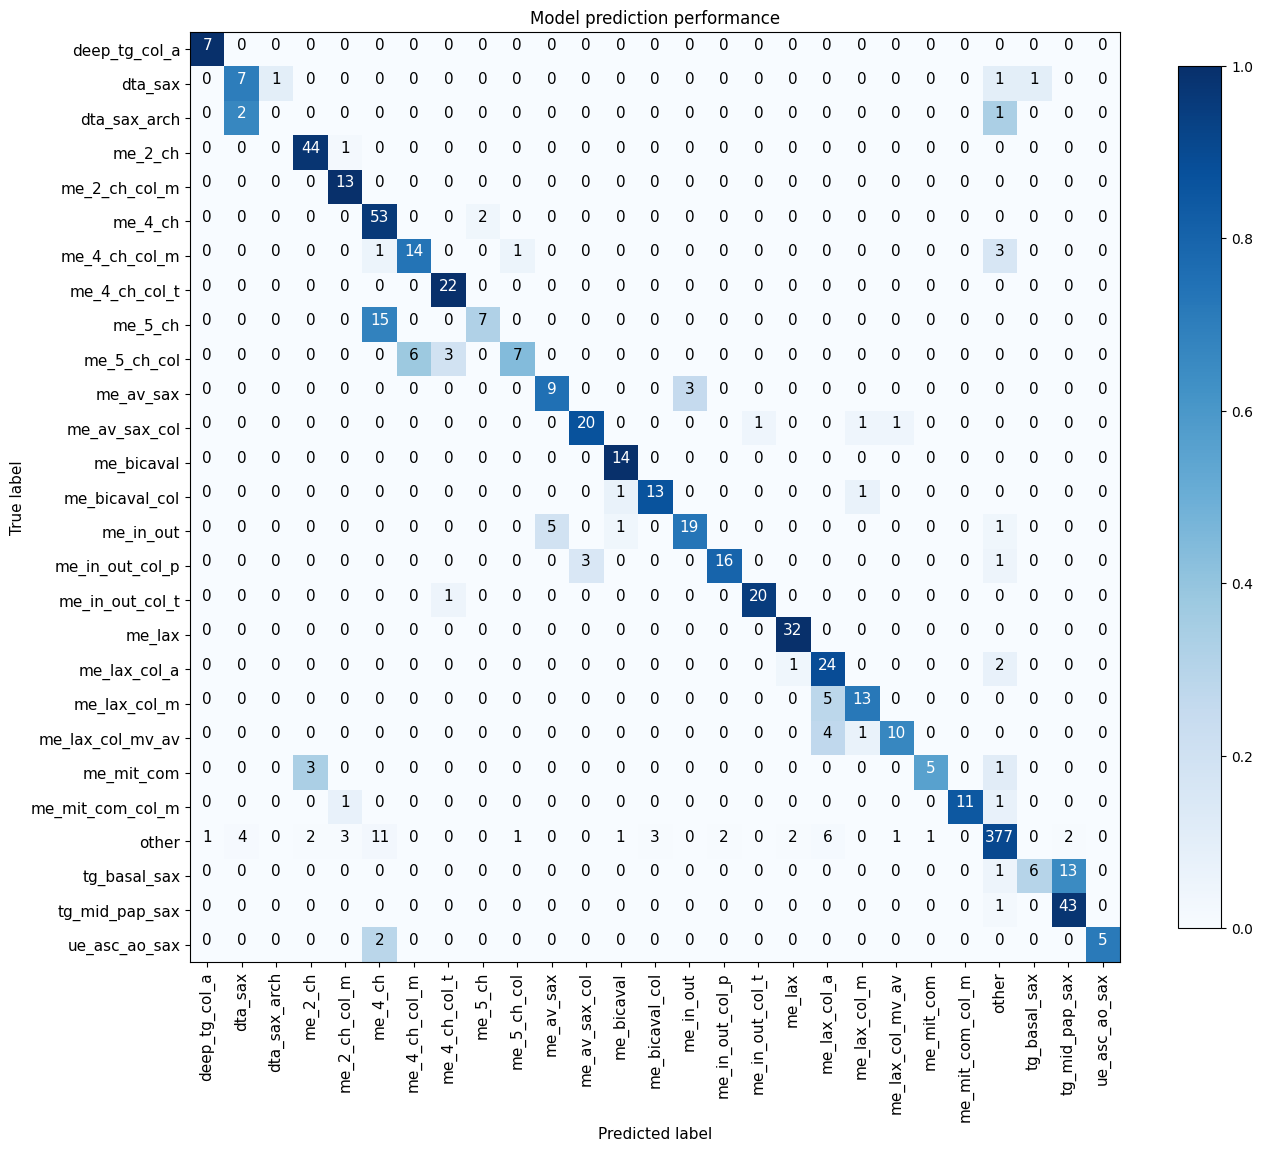

In [33]:
# Compute confusion matrix
cm = confusion_matrix(test_labels, test_labels_predicted, normalize='true')
cm2 = confusion_matrix(test_labels, test_labels_predicted)

# Plot normalized confusion matrix
plt.figure(figsize = (15, 14))
plot_confusion_matrix(cm=cm, classes=class_names, cm2=cm2, normalize=True,
                      title='Model prediction performance')

plt.savefig('model_prediction_view_confusion_matrix.png', dpi=300)

In [34]:
testy = test_labels
yhat_classes = test_labels_predicted
yhat_classes_onehot = np.eye(np.max(yhat_classes) + 1)[yhat_classes]
yhat_probs = test_predictions
yhat_probs = normalize(torch.sigmoid(torch.tensor((yhat_probs))), axis=1, norm='l1')

In [35]:
import sklearn.metrics
sklearn.metrics.roc_auc_score(yhat_classes_onehot, yhat_probs, average='micro', sample_weight=None, max_fpr=None, multi_class='ovr', labels=None)

0.9485816574176363

In [36]:
sklearn.metrics.roc_auc_score(yhat_classes_onehot, yhat_probs, average='micro', sample_weight=None, max_fpr=None, multi_class='ovr', labels=None)

0.9485816574176363

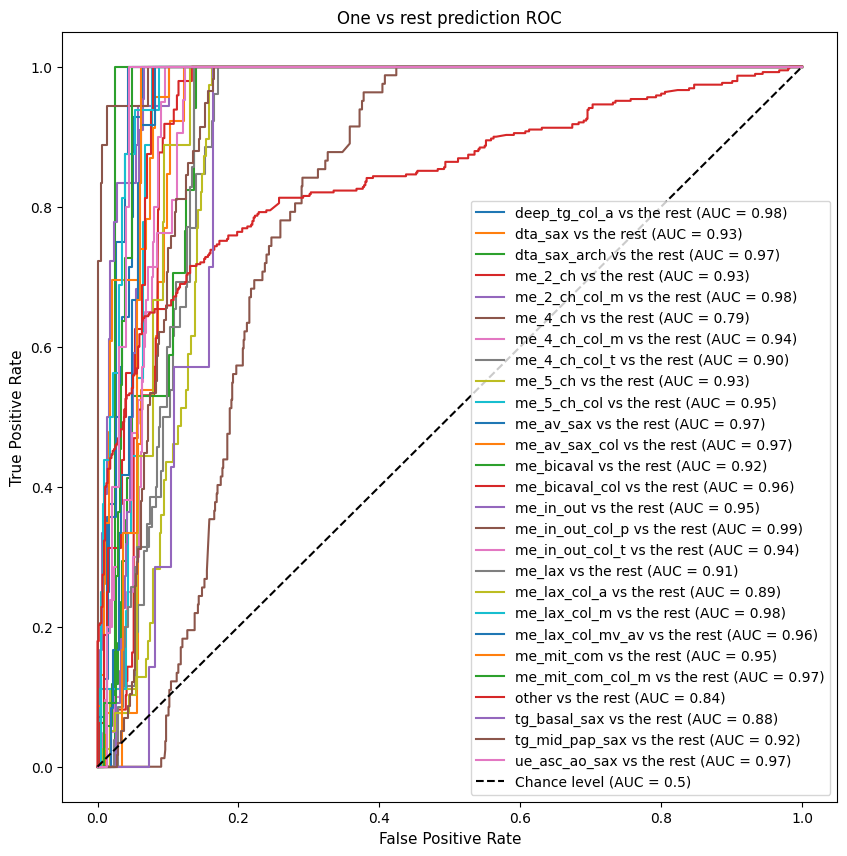

In [45]:
from sklearn.metrics import RocCurveDisplay

i = 0
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
chance_level=False

for i in range(len(class_names)):
    if i==len(class_names)-1:
        chance_level=True

    RocCurveDisplay.from_predictions(
        yhat_classes_onehot[:, i],
        yhat_probs[:, i],
        name=f"{class_names[i]} vs the rest",
        # color="darkorange",
        plot_chance_level=chance_level,
        ax=ax,
    )
    
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.set_title('One vs rest prediction ROC', fontsize=12)
plt.savefig('model_prediction_view_roc_curve.png', dpi=300)

In [ ]:
false_positives = (test_labels_predicted == 0) & (test_labels == 1)
false_negatives = (test_labels_predicted == 1) & (test_labels == 0)

fpos_indices = list(np.where(false_positives)[0])
fneg_indices = list(np.where(false_negatives)[0])

 Examples of false positives

In [ ]:
def indices_by_clip(clip_index_list, test_dataset):
    indice_order = index_natsorted(test_dataset.imgs)
    test_dataset_ordered = torch.utils.data.Subset(test_dataset, indices=indice_order)

    string = ''
    indices = []
    frames_list = []
    
    regex = r"^[^_]*_[^_]*_"

    count = -1
    for i in tqdm(range(len(test_dataset_ordered))):
        path = test_dataset_ordered.dataset.imgs[i][0]
        new_string = os.path.split(path)[1]
        match = re.search(regex, new_string).group(0)
        if string != match: # if at new video clip, increment count
            string = match
            if count in clip_index_list:
                indices.append(frames_list.copy()) # if switching to a new clip and count is in fpositives, append the current frames list and reset
                frames_list = []
            count += 1
        if count in clip_index_list: # if clip in list of false positives, append frame index to frames_list
            frames_list.append(i)
    
    return indices
    
def display_image_subset(clip_index_list, test_dataset, title = None):
    
    indices = indices_by_clip(clip_index_list, test_dataset)
    
    indice_order = index_natsorted(test_dataset.imgs)
    test_dataset_ordered = torch.utils.data.Subset(test_dataset, indices=indice_order)

    rng = np.random.default_rng()
    numrows = max(len(clip_index_list),2)
    fig, ax = plt.subplots(numrows, 4, tight_layout=True, figsize=(10, 6))
    if title: plt.suptitle(title)

    for i in range(len(indices)):
        disp_indices = rng.choice(indices[i], 4, replace=False)
        ax[i][0].imshow(test_dataset_ordered[disp_indices[0]][0][0,:,:], cmap = 'gray')
        ax[i][1].imshow(test_dataset_ordered[disp_indices[1]][0][0,:,:], cmap = 'gray')
        ax[i][2].imshow(test_dataset_ordered[disp_indices[2]][0][0,:,:], cmap = 'gray')
        ax[i][3].imshow(test_dataset_ordered[disp_indices[3]][0][0,:,:], cmap = 'gray')
    plt.show()


In [ ]:
display_image_subset(fneg_indices, test_dataset, title = 'me bicaval, false negatives')

In [ ]:
display_image_subset(fpos_indices, test_dataset, title = 'me bicaval, false positives')

In [ ]:
def display_image_subset(clip_index_list, test_dataset):
    
    indices = indices_by_clip(clip_index_list, test_dataset)
    
    indice_order = index_natsorted(test_dataset.imgs)
    test_dataset_ordered = torch.utils.data.Subset(test_dataset, indices=indice_order)

    rng = np.random.default_rng()
    numrows = len(
    fig, ax = plt.subplots(2, 4, tight_layout=True, figsize=(10, 4))

    for i in range(len(indices)):
        disp_indices = rng.choice(indices[i], 4, replace=False)
        ax[i][0].imshow(test_dataset_ordered[disp_indices[0]][0][0,:,:])
        ax[i][1].imshow(test_dataset_ordered[disp_indices[1]][0][0,:,:])
        ax[i][2].imshow(test_dataset_ordered[disp_indices[2]][0][0,:,:])
        ax[i][3].imshow(test_dataset_ordered[disp_indices[3]][0][0,:,:])
    plt.show()

In [ ]:
disp_indices

In [ ]:
plt.imshow(test_dataset_ordered[i][0][0,:,:])

 Examples of false negatives

In [ ]:
false_negatives_ind = (test_labels_predicted == 1) & (test_labels == 0)
false_negatives = np.random.choice(np.where(false_negatives_ind)[0], 16)

plt.figure(figsize=(10, 10))
i = 0
for index in false_negatives:
  ax = plt.subplot(4, 4, i + 1)
  ax.set_aspect('equal')
  plt.imshow(test_data[index][0].astype('uint8'))
  plt.axis('off')
  i += 1
plt.savefig('../data/test_false_negatives.png', pad_inches=0, bbox_inches=None, dpi=300)
plt.show()




In [ ]:
print(model.summary())

In [ ]:
plot_model(model, to_file='../data/model.png', show_shapes=True, show_layer_names=True)

In [12]:
# test_labels_predicted, test_predictions, test_labels

In [13]:
test_labels[:10]

array([0., 0., 0., 0., 0., 0., 0., 1., 1., 1.])

In [14]:
test_labels_predicted[:10]

array([ 0,  0,  0,  0,  0,  0,  0,  1, 23,  2])

In [17]:
np.histogram(test_labels_predicted)

(array([ 22, 149,  46,  32,  40,  56,  95,  28, 407,  70]),
 array([ 0. ,  2.6,  5.2,  7.8, 10.4, 13. , 15.6, 18.2, 20.8, 23.4, 26. ]))

In [18]:
np.histogram(test_labels)

(array([ 20, 113,  41,  50,  37,  61,  80,  33, 439,  71]),
 array([ 0. ,  2.6,  5.2,  7.8, 10.4, 13. , 15.6, 18.2, 20.8, 23.4, 26. ]))

(array([ 22., 149.,  46.,  32.,  40.,  56.,  95.,  28., 407.,  70.]),
 array([ 0. ,  2.6,  5.2,  7.8, 10.4, 13. , 15.6, 18.2, 20.8, 23.4, 26. ]),
 <BarContainer object of 10 artists>)

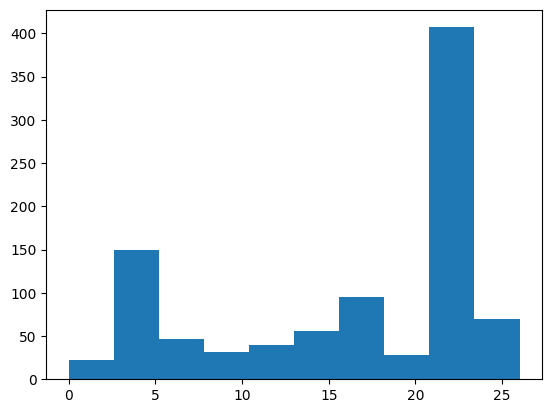

In [19]:
plt.hist(test_labels_predicted)

In [27]:
len(class_names)

27

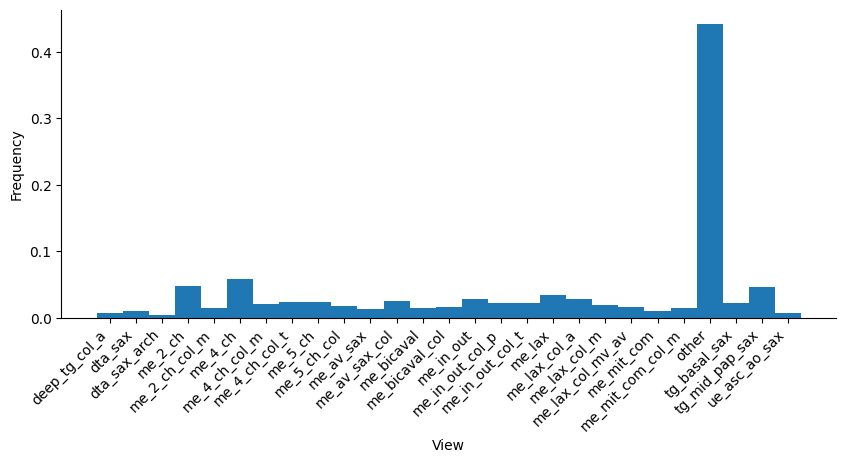

In [24]:
fig, ax = plt.subplots(figsize=(10, 4))
counts, bins, _ = ax.hist(test_labels, bins=np.arange(len(class_names)+1)-0.5, density=True)
ax.set_xticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.set_xlabel('View')
ax.set_ylabel('Frequency')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

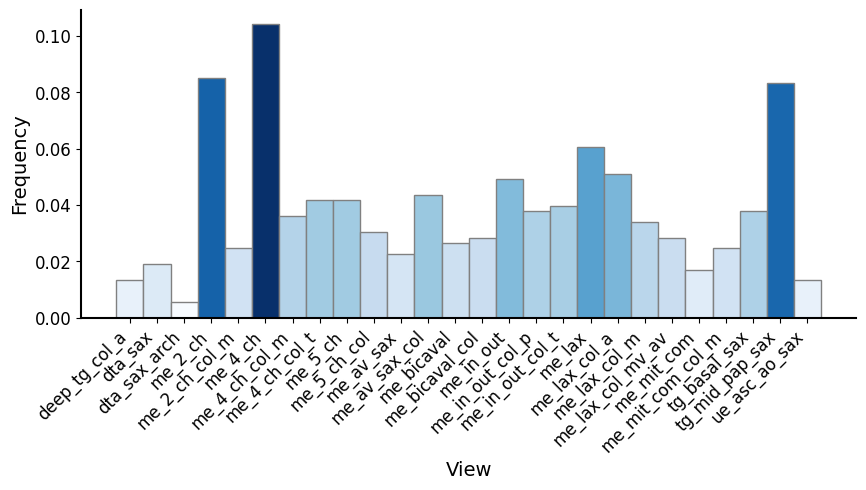

In [53]:
fig, ax = plt.subplots(figsize=(10, 4))
# Filter out 'other' class (index 23 based on class_names output) and adjust indices
mask = test_labels != 23
filtered_labels = test_labels[mask]
# Shift labels above 23 down by 1 to account for removed 'other' class
filtered_labels = np.where(filtered_labels > 23, filtered_labels - 1, filtered_labels)
filtered_class_names = [name for name in class_names if name != 'other']
counts, bins, _ = ax.hist(filtered_labels, bins=np.arange(len(filtered_class_names)+1)-0.5, density=True)
ax.set_xticks(range(len(filtered_class_names)))
ax.set_xticklabels(filtered_class_names, rotation=45, ha='right')
ax.set_xlabel('View')
ax.set_ylabel('Frequency')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# Increase font sizes
ax.tick_params(axis='both', labelsize=12)
ax.set_xlabel('View', fontsize=14)
ax.set_ylabel('Frequency', fontsize=14)
# Make axis lines thicker
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)
# Color bars by height using a blue colormap and add outlines
norm = plt.Normalize(counts.min(), counts.max())
colors = plt.cm.Blues(norm(counts))
for patch, color in zip(ax.patches, colors):
    patch.set_facecolor(color)
    patch.set_edgecolor('gray')
    patch.set_linewidth(1)
    
plt.savefig('class_frequency.png', dpi=300,bbox_inches='tight')

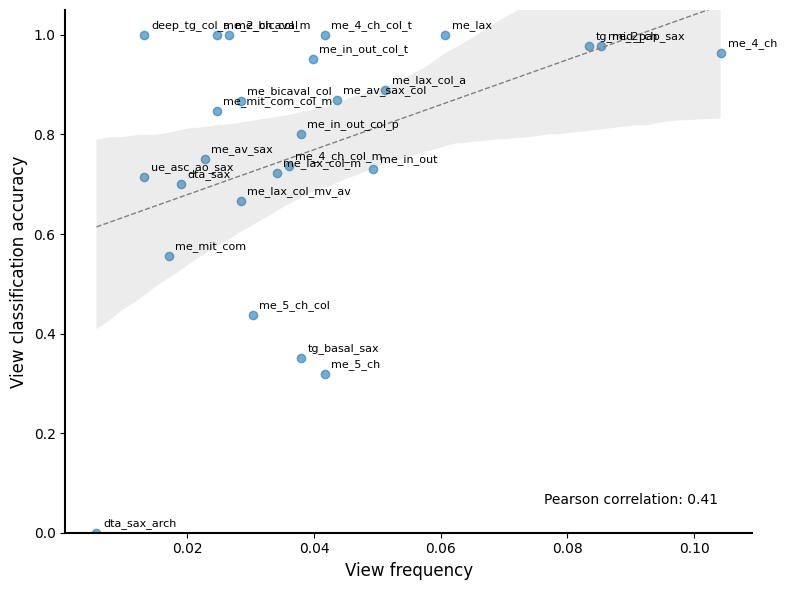

In [52]:
import seaborn as sns
from scipy import stats
# Filter out 'other' class (index 23)
mask = test_labels != 23
filtered_labels = test_labels[mask]
filtered_predictions = test_labels_predicted[mask]
# Shift labels above 23 down by 1 to account for removed 'other' class
filtered_labels = np.where(filtered_labels > 23, filtered_labels - 1, filtered_labels)
filtered_predictions = np.where(filtered_predictions > 23, filtered_predictions - 1, filtered_predictions)
filtered_class_names = [name for name in class_names if name != 'other']

# Calculate per-class accuracy
per_class_correct = np.zeros(26)  # 27-1 classes after removing 'other'
per_class_total = np.zeros(26)

for pred, true in zip(filtered_predictions, filtered_labels):
    per_class_total[int(true)] += 1
    if pred == true:
        per_class_correct[int(true)] += 1

per_class_accuracy = per_class_correct / per_class_total

# Calculate class frequencies
class_frequencies = np.bincount(filtered_labels.astype(int)) / len(filtered_labels)

# Calculate correlation coefficient
slope, intercept, r_value, p_value, std_err = stats.linregress(class_frequencies, per_class_accuracy)

# Create plot with seaborn
plt.figure(figsize=(8, 6))
sns.regplot(x=class_frequencies, y=per_class_accuracy, 
            scatter_kws={'alpha':0.6}, 
            line_kws={'color': 'gray', 'linestyle': '--', 'linewidth': 1},
            ci=95)

# Add labels for each point
for i, (freq, acc) in enumerate(zip(class_frequencies, per_class_accuracy)):
    plt.annotate(filtered_class_names[i], (freq, acc),
                xytext=(5, 5), textcoords='offset points',
                fontsize=8)

# Customize plot
plt.xlabel('View frequency', fontsize=12)
plt.ylabel('View classification accuracy', fontsize=12)
plt.ylim(0, 1.05)

# Add correlation coefficient
plt.text(0.95, 0.05, f'Pearson correlation: {r_value:.2f}', 
         transform=plt.gca().transAxes,
         horizontalalignment='right',
         verticalalignment='bottom')

# Remove top and right spines
sns.despine()

# Make remaining spines thicker
plt.gca().spines['left'].set_linewidth(1.5)
plt.gca().spines['bottom'].set_linewidth(1.5)

plt.tight_layout()

plt.savefig('class_accuracy_vs_frequency.png', dpi=300, bbox_inches='tight')


In [45]:
per_class_accuracy

array([1.        , 0.7       , 0.        , 0.97777778, 1.        ,
       0.96363636, 0.73684211, 1.        , 0.31818182, 0.4375    ,
       0.75      , 0.86956522, 1.        , 0.86666667, 0.73076923,
       0.8       , 0.95238095, 1.        , 0.88888889, 0.72222222,
       0.66666667, 0.55555556, 0.84615385, 0.35      , 0.97727273,
       0.71428571])